# Integration (alignment) of clonal embeddings

To analyse several datasets together, there are two routes:

1. **Integrate the cells first**, then build one clonal embedding from the joint expression space.
2. **Build a clonal embedding per dataset**, then integrate the clonal embeddings.

The first route is the most direct, but integrating cells from very different contexts (tissues, cohorts, technologies) is hard and risks over-correcting real biological differences. This notebook shows the second route.

**Why clonal embeddings can be aligned with a simple transformation.** A clone2vec embedding is defined only up to a linear transformation: training the same model twice can give rotated, stretched or shifted coordinates that describe exactly the same relationships between clones. Two datasets with similar clonal behaviours therefore give "the same map in different coordinates". To align them, we need:

* **anchors:** pairs of clones, one from each dataset, that we believe behave alike. We find them from the clones' **average gene expression**, which is independent of the embeddings.
* **a transformation:** the affine map (linear transformation plus shift) that brings the anchors of one dataset as close as possible to their partners in the other.

An affine map keeps the linear structure of the clonal space intact. For example, a clone that mixes two behaviours still sits between the clones showing each behaviour alone.

**How we test it.** In the Weinreb et al. in vitro hematopoiesis data, the cells of day 4 come from two wells. We build:

* a **ground truth**: one embedding of both wells together, from an already integrated expression space;
* two **separate** embeddings, one per well, which we then align.

If the alignment works, the aligned embedding should look like the ground truth.

## Setup

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

In [2]:
adata = c2v.datasets.Weinreb_in_vitro(embedding_type="gex")

using gene expression embedding


## Step 1: Ground truth embedding

We take all day-4 cells of both wells and run the standard workflow. Clonal units are defined per `time:well:clone`, as in the introductory notebook, so the same barcode in two wells gives two separate units.

In [3]:
adata_d4 = adata[(adata.obs["Time point"] == 4)].copy()
clones_d4 = c2v.pp.clones_adata(adata_d4, obs_name="time:well:clone")

creating clone-level AnnData
    selected 1943 clones (>= 3)
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label


In [4]:
c2v.tl.clonal_nn(adata_d4, clones_d4, use_rep="X_pca_harmony")

computing clone-to-clone adjacency graph
    finished (0:00:45): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [5]:
c2v.tl.clone2vec(clones_d4)

fitting clone2vec embeddings
    SG epochs:  16%|█▌        | 79/500 [04:03<21:39,  3.09s/it, loss=4.9731, Δ=9.38e-05]
    early stopping at epoch 80
    finished (0:04:05): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


In [6]:
sc.pp.neighbors(clones_d4, use_rep="clone2vec")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:04)


In [7]:
sc.tl.umap(clones_d4)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:03)


In [8]:
c2v.pp.transfer_annotation(adata_d4, clones_d4, annotation_obs_adata="Well")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_Well'] categorical labels


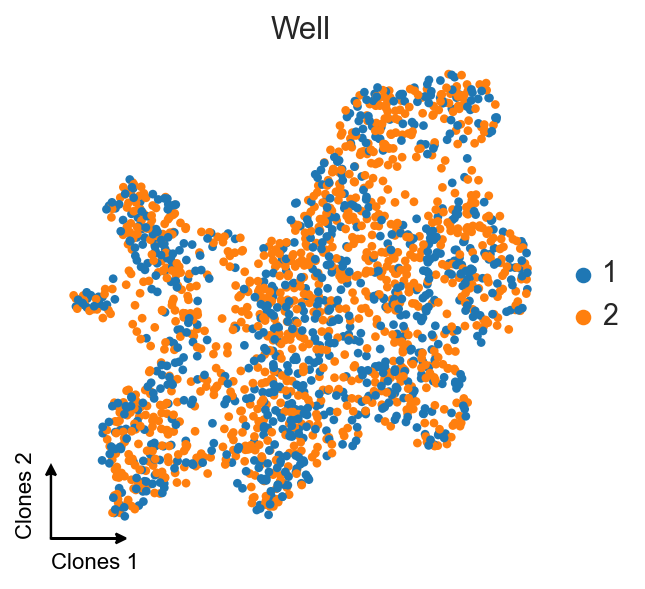

In [9]:
ax = sc.pl.umap(clones_d4, color="gex_Well", title="Well", frameon=False, show=False)
c2v.pl.embedding_axis(ax, label="Clones")

Clones of the two wells are well mixed: the expression space was already batch-corrected, so the ground truth has no well effect.

In [10]:
sc.tl.leiden(clones_d4, resolution=1, flavor="igraph", n_iterations=2)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


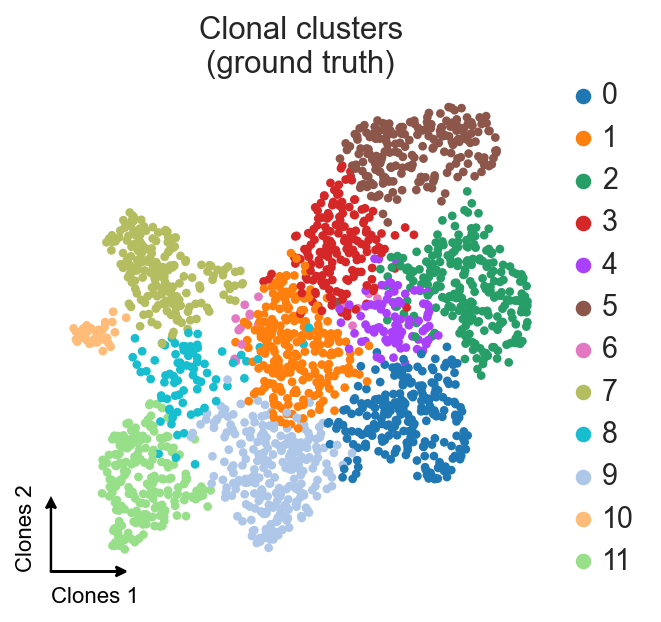

In [11]:
ax = sc.pl.umap(clones_d4, color="leiden", title="Clonal clusters\n(ground truth)",
                frameon=False, show=False)

c2v.pl.embedding_axis(ax, label="Clones")

These clusters are our reference: an aligned embedding should reproduce them.

## Step 2: Separate embeddings per well

Now we pretend that the two wells are separate datasets and build an independent clonal embedding for each one.

### Well 1

In [12]:
adata_d4_w1 = adata[(adata.obs["Time point"] == 4) & (adata.obs.Well == 1)].copy()
clones_d4_w1 = c2v.pp.clones_adata(adata_d4_w1, obs_name="time:well:clone")

creating clone-level AnnData
    selected 827 clones (>= 3)
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label


In [13]:
c2v.tl.clonal_nn(adata_d4_w1, clones_d4_w1, use_rep="X_pca_harmony")

computing clone-to-clone adjacency graph
    finished (0:00:03): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [14]:
c2v.tl.clone2vec(clones_d4_w1)

fitting clone2vec embeddings
    SG epochs:  23%|██▎       | 116/500 [02:10<07:11,  1.12s/it, loss=3.9988, Δ=7.96e-05]
    early stopping at epoch 117
    finished (0:02:10): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


We don't need a UMAP here: the alignment works directly in the `clone2vec` space.

What we do need is each clone's **average gene expression**, to find the anchors. We also record the well of each clone.

In [15]:
clones_d4_w1 = c2v.pp.transfer_expression(adata_d4_w1, clones_d4_w1)

summarizing expression at clone level: 
    using `adata.X` as expression source
    finished (0:00:01): created clone-level AnnData with
     .X aggregated expression matrix (clones × genes)
     .uns['transfer_expression'] dict with 'strategy'
     .uns['mask_key'] string with obsm key for boolean mask of clones with non-zero cells
     .obsm['proportions'] dataframe of features
     .obsm['counts'] dataframe of features


In [16]:
c2v.pp.transfer_annotation(adata_d4_w1, clones_d4_w1, annotation_obs_adata="Well")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_Well'] categorical labels


### Well 2

The same steps for the second well.

In [17]:
adata_d4_w2 = adata[(adata.obs["Time point"] == 4) & (adata.obs.Well == 2)].copy()
clones_d4_w2 = c2v.pp.clones_adata(adata_d4_w2, obs_name="time:well:clone")

creating clone-level AnnData
    selected 1116 clones (>= 3)
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label


In [18]:
c2v.tl.clonal_nn(adata_d4_w2, clones_d4_w2, use_rep="X_pca_harmony")

computing clone-to-clone adjacency graph
    finished (0:00:03): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [19]:
c2v.tl.clone2vec(clones_d4_w2)

fitting clone2vec embeddings
    SG epochs:  18%|█▊        | 89/500 [02:48<12:56,  1.89s/it, loss=4.6069, Δ=4.08e-05]
    early stopping at epoch 90
    finished (0:02:48): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


In [20]:
clones_d4_w2 = c2v.pp.transfer_expression(adata_d4_w2, clones_d4_w2)

summarizing expression at clone level: 
    using `adata.X` as expression source
    finished (0:00:02): created clone-level AnnData with
     .X aggregated expression matrix (clones × genes)
     .uns['transfer_expression'] dict with 'strategy'
     .uns['mask_key'] string with obsm key for boolean mask of clones with non-zero cells
     .obsm['proportions'] dataframe of features
     .obsm['counts'] dataframe of features


In [21]:
c2v.pp.transfer_annotation(adata_d4_w2, clones_d4_w2, annotation_obs_adata="Well")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_Well'] categorical labels


## Step 3: Find anchors

Integration starts here. We look for pairs of clones, one in each well, with similar average expression. There are three steps:

1. build an expression space shared by the clones of both wells;
2. find **mutual nearest neighbours** (MNN) between the wells in this space;
3. align the clone2vec embeddings using these pairs as anchors (Step 4).

First, we merge the two clone-level objects and select highly variable genes, accounting for the well.

In [22]:
clones_d4_w1w2 = sc.concat([clones_d4_w1, clones_d4_w2])
sc.pp.highly_variable_genes(clones_d4_w1w2, batch_key="gex_Well", n_top_genes=3000)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


Next, we scale each gene **within each well separately**. This removes well-wide shifts in mean expression, so that clones are matched by their *relative* expression profile. It corrects more aggressively than scaling both wells together; there's no hard rule, and either can work.

In [23]:
# Subselection of HVGs and saving all genes
clones_d4_w1w2.raw = clones_d4_w1w2.copy()
clones_d4_w1w2 = clones_d4_w1w2[:, clones_d4_w1w2.var.highly_variable].copy()

# Densification of the .X matrix for the further scaling
clones_d4_w1w2.X = clones_d4_w1w2.X.toarray()

# Per-dataset scaling
for well in [1, 2]:
    sc.pp.scale(clones_d4_w1w2, max_value=10, mask_obs=(clones_d4_w1w2.obs.gex_Well == well).values)

Then we compute a PCA on the scaled average expression. This is the space where we look for anchors. If it still showed a strong batch effect, it could be corrected further, e.g. with Harmony.

In [24]:
sc.pp.pca(clones_d4_w1w2, n_comps=20)

computing PCA
    with n_comps=20
    finished (0:00:00)


Now the anchors. Two clones form a mutual nearest neighbour pair if each is among the other's `k=5` nearest neighbours **in the other well**. Requiring the relation to be mutual protects against forced matches: a clone whose behaviour has no counterpart in the other well simply gets no partner. `k_trim=1` keeps at most one partner per clone, the best one.

In [25]:
c2v.tl.find_mnn(clones_d4_w1w2, batch_key="gex_Well", use_rep="X_pca", k_trim=1, k=5)

finding MNN anchors across batches: 
    using `clones.obsm['X_pca']` for neighbor search
    pairwise MNNs: 100%|██████████| 1/1 [00:07<00:00,  7.20s/it]
    finished (0:00:07): added
     .obsp['mnn'] symmetric sparse matrix.
     .uns['simple_mnn'] integration order and parameters.


## Step 4: Align

`c2v.tl.align` fits an affine transformation by weighted least squares on the anchor pairs: it maps the smaller batch onto the larger one so that anchor partners end up as close as possible. Pairs that are closer in each other's neighbour lists get more weight. The aligned embedding is stored in `clones.obsm["clone2vec_pa"]`.

In [26]:
c2v.tl.align(clones_d4_w1w2)

aligning representation using weighted affine least-squares and MNN anchors
    finished (0:00:00): added
     .obsm['clone2vec_pa'] aligned representation.


Let's check how well the wells are mixed in the aligned embedding.

In [27]:
sc.pp.neighbors(clones_d4_w1w2, use_rep="clone2vec_pa")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)


In [28]:
sc.tl.umap(clones_d4_w1w2)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:03)


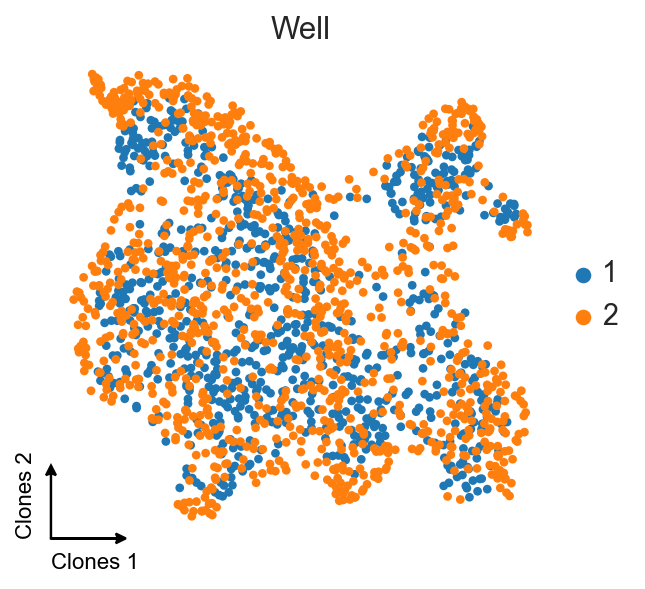

In [29]:
ax = sc.pl.umap(clones_d4_w1w2, color="gex_Well", title="Well", frameon=False, show=False)
c2v.pl.embedding_axis(ax, label="Clones")

**What to look for:** the wells largely overlap, but some regions are still dominated by one well. A single affine map can't fix every local difference.

## Step 5 (optional): Remove the remaining batch effect

All clones now live in one space, so we can apply standard batch correction to it, here Harmony.

**This step isn't necessary, and Harmony is a non-linear transformation, so the resulting embedding can violate the linear properties of the clonal space described in the paper.** Use it for visualization and clustering, and use `clone2vec_pa` when those linear properties matter, e.g. for archetypal analysis.

In [32]:
import harmonypy as hm

harmony_out = hm.run_harmony(
    data_mat=clones_d4_w1w2.obsm["clone2vec_pa"].copy(),
    meta_data=clones_d4_w1w2.obs,
    vars_use="gex_Well",
)

clones_d4_w1w2.obsm["clone2vec_pa_harmony"] = harmony_out.Z_corr

2026-05-02 14:15:13,021 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-05-02 14:15:13,022 - harmonypy - INFO -   Parameters:
2026-05-02 14:15:13,024 - harmonypy - INFO -     max_iter_harmony: 10
2026-05-02 14:15:13,025 - harmonypy - INFO -     max_iter_kmeans: 20
2026-05-02 14:15:13,027 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-05-02 14:15:13,028 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-05-02 14:15:13,030 - harmonypy - INFO -     nclust: 65
2026-05-02 14:15:13,031 - harmonypy - INFO -     block_size: 0.05
2026-05-02 14:15:13,033 - harmonypy - INFO -     lamb: [1. 1.]
2026-05-02 14:15:13,035 - harmonypy - INFO -     theta: [2. 2.]
2026-05-02 14:15:13,037 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-05-02 14:15:13,039 - harmonypy - INFO -     verbose: True
2026-05-02 14:15:13,040 - harmonypy - INFO -     random_state: 0
2026-05-02 14:15:13,042 - harmonypy - INFO -   Data: 10 PCs × 1943 cells
2026-05-02 14:15:13,043 - harmonypy - INFO 

In [33]:
sc.pp.neighbors(clones_d4_w1w2, use_rep="clone2vec_pa_harmony")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)


In [34]:
sc.tl.umap(clones_d4_w1w2)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


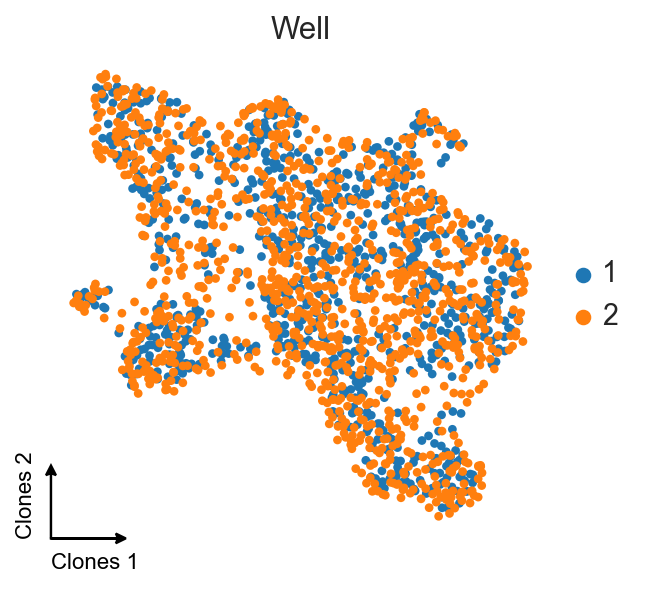

In [35]:
ax = sc.pl.umap(clones_d4_w1w2, color="gex_Well", title="Well", frameon=False, show=False)
c2v.pl.embedding_axis(ax, label="Clones")

After Harmony, the two wells are mixed throughout.

## Step 6: Compare with the ground truth

The UMAP and Leiden clusters below are computed from the aligned and Harmony-corrected embedding. We compare them with the ground truth in a 2 × 2 grid:

* **columns** are the layouts (ground truth UMAP left, aligned UMAP right);
* **rows** are the clusterings (ground truth clusters on top, aligned clusters below).

If the two embeddings agree, each clustering forms compact regions on both layouts. Cluster numbers are arbitrary and don't need to match.

In [36]:
sc.tl.leiden(clones_d4_w1w2, resolution=1, flavor="igraph", n_iterations=2)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


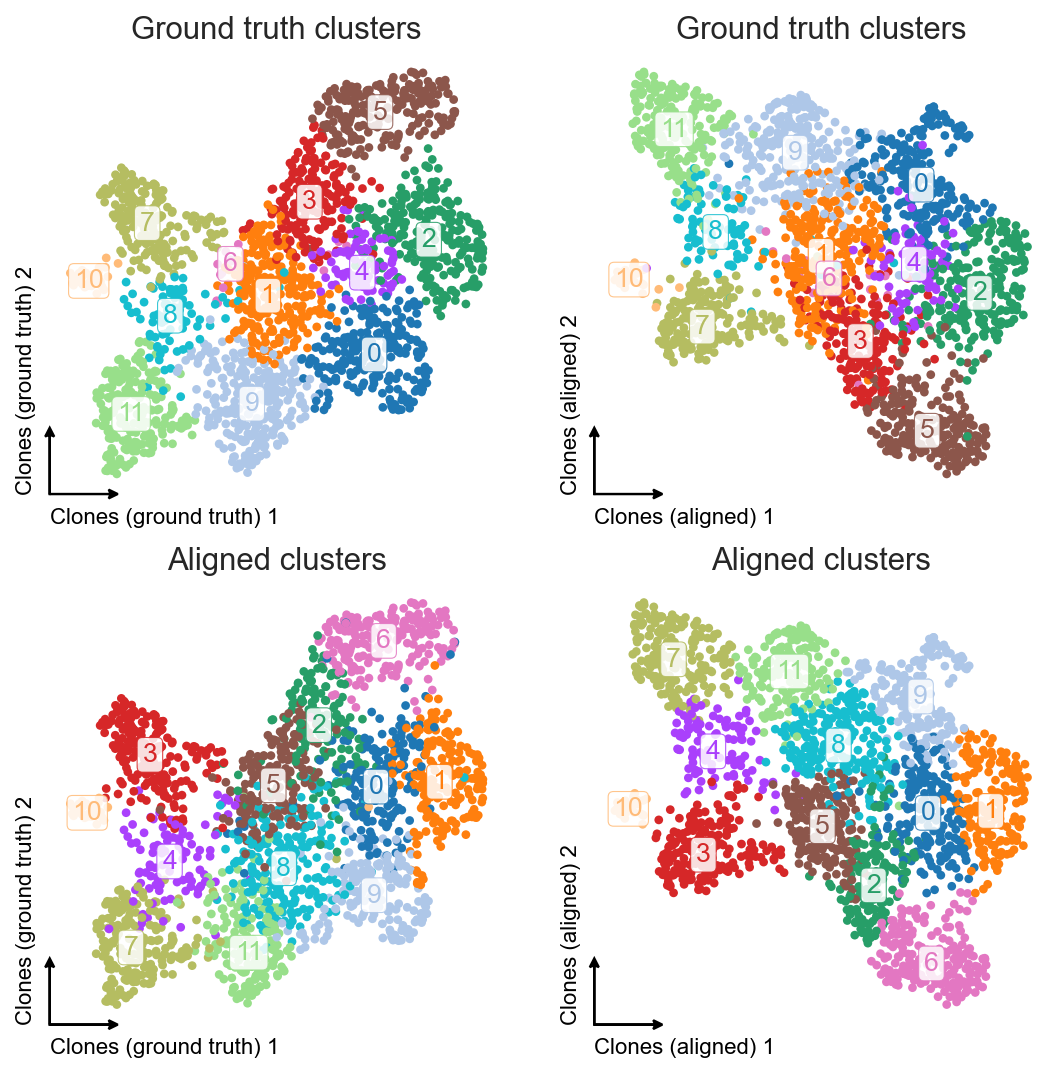

In [37]:
clones_d4.obsm["X_umap_aligned"] = clones_d4_w1w2[clones_d4.obs_names].obsm["X_umap"].copy()
clones_d4.obs["leiden_aligned"] = clones_d4_w1w2[clones_d4.obs_names].obs.leiden.copy()

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(8, 8))

sc.pl.embedding(
    clones_d4,
    ax=axes[0, 0],
    show=False,
    basis="X_umap",
    frameon=False,
    color="leiden",
    title="Ground truth clusters",
)
c2v.pl.fancy_legend(axes[0, 0], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[0, 0], label="Clones (ground truth)")

sc.pl.embedding(
    clones_d4,
    ax=axes[0, 1],
    show=False,
    basis="X_umap_aligned",
    frameon=False,
    color="leiden",
    title="Ground truth clusters",
)
c2v.pl.fancy_legend(axes[0, 1], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[0, 1], label="Clones (aligned)")

sc.pl.embedding(
    clones_d4,
    ax=axes[1, 0],
    show=False,
    basis="X_umap",
    frameon=False,
    color="leiden_aligned",
    title="Aligned clusters",
)
c2v.pl.fancy_legend(axes[1, 0], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[1, 0], label="Clones (ground truth)")

sc.pl.embedding(
    clones_d4,
    ax=axes[1, 1],
    show=False,
    basis="X_umap_aligned",
    frameon=False,
    color="leiden_aligned",
    title="Aligned clusters",
)
c2v.pl.fancy_legend(axes[1, 1], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[1, 1], label="Clones (aligned)")

The orientation of a UMAP carries no meaning. Flipping the aligned layout vertically makes it easier to compare by eye.

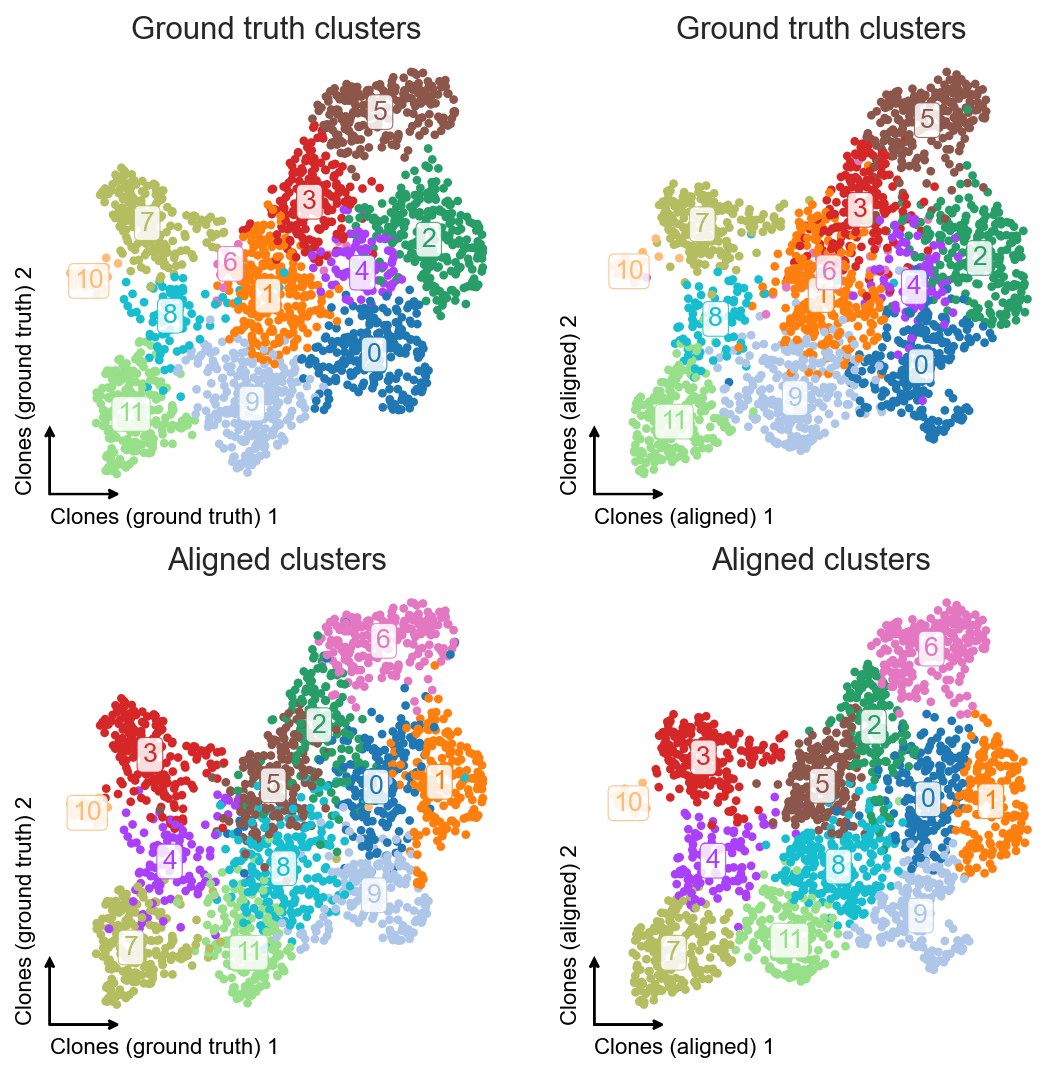

In [39]:
clones_d4.obsm["X_umap_aligned"][:, 1] = -clones_d4.obsm["X_umap_aligned"][:, 1]

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(8, 8))

sc.pl.embedding(
    clones_d4,
    ax=axes[0, 0],
    show=False,
    basis="X_umap",
    frameon=False,
    color="leiden",
    title="Ground truth clusters",
)
c2v.pl.fancy_legend(axes[0, 0], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[0, 0], label="Clones (ground truth)")

sc.pl.embedding(
    clones_d4,
    ax=axes[0, 1],
    show=False,
    basis="X_umap_aligned",
    frameon=False,
    color="leiden",
    title="Ground truth clusters",
)
c2v.pl.fancy_legend(axes[0, 1], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[0, 1], label="Clones (aligned)")

sc.pl.embedding(
    clones_d4,
    ax=axes[1, 0],
    show=False,
    basis="X_umap",
    frameon=False,
    color="leiden_aligned",
    title="Aligned clusters",
)
c2v.pl.fancy_legend(axes[1, 0], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[1, 0], label="Clones (ground truth)")

sc.pl.embedding(
    clones_d4,
    ax=axes[1, 1],
    show=False,
    basis="X_umap_aligned",
    frameon=False,
    color="leiden_aligned",
    title="Aligned clusters",
)
c2v.pl.fancy_legend(axes[1, 1], center_loc=True, textsize=12)
c2v.pl.embedding_axis(axes[1, 1], label="Clones (aligned)")

**What to look for:** the ground truth clusters keep their shape and their relative positions on the aligned layout (top row), and the aligned clusters map onto compact regions of the ground truth layout (bottom row). Some borders between neighbouring clusters shift a little, as you would expect from two independently trained embeddings.

## Conclusion

Aligning separately built clonal embeddings recovers almost the same clonal map as building one embedding from integrated cells, without ever integrating the cells. This is useful when datasets are too different for cell-level integration but share clonal behaviours, such as T cell clones from different tumour types.